In [ ]:
%matplotlib inline

# Notebook 1 — Build a FODO ring

**Build an electron storage ring from identical FODO cells**. 

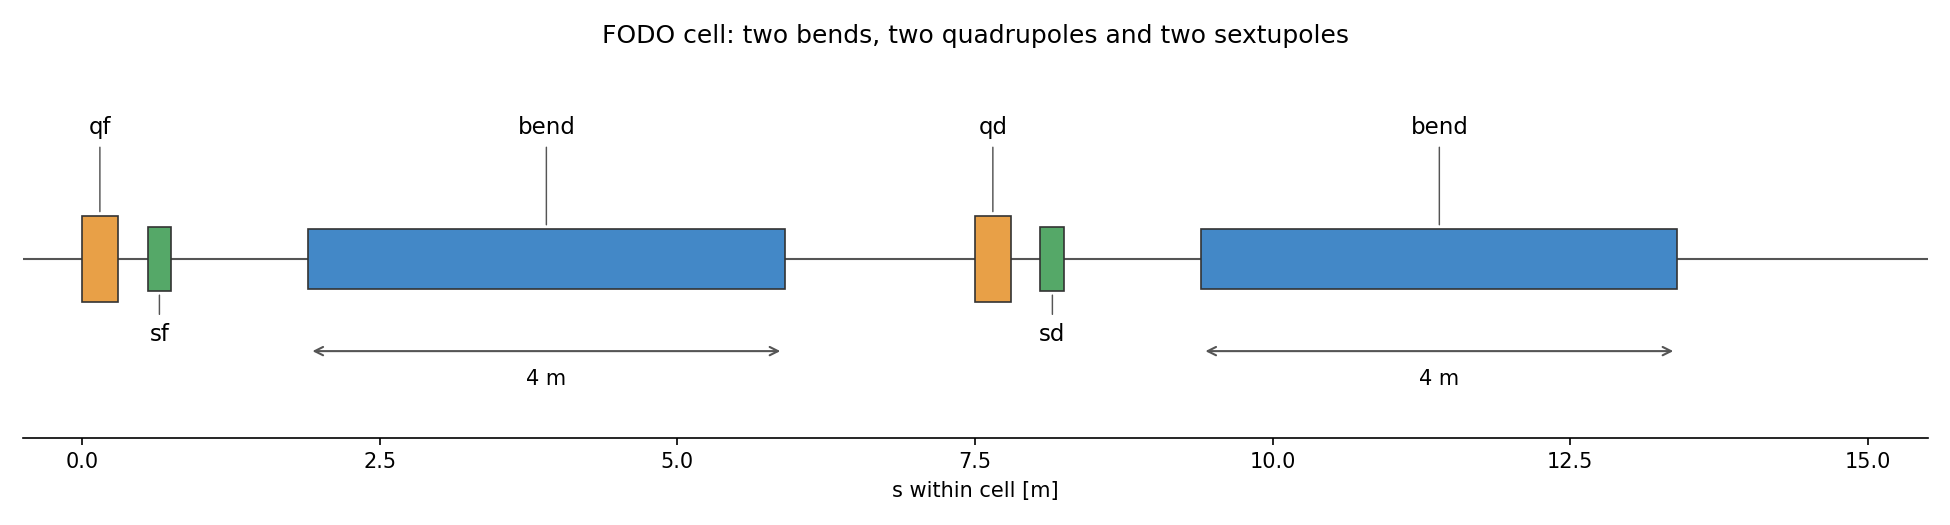

Indicative cell layout.

## Lattice specifications

| Parameter | Value |
|---|---:|
| Reference particle | Electron |
| Reference total energy | 1.7 GeV |
| Ring circumference | 240 m |
| Number of identical FODO cells | 16 |
| Phase advance per cell (horizontal / vertical) | 91° / 92° |
| Dipole type | Sector bend (`xt.Bend`) |
| Dipole length | 4.0 m |
| Quadrupole length | 0.30 m |
| Sextupole length | 0.20 m |
| Ring chromaticity | 0.5 / 0.5 |

### Imports

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt

### Create xsuite environment

In [ ]:
env = xt.Environment()
env.set_particle_ref('electron', energy0=1.7e9)

### Geometry parameters

In [ ]:
# env['angle_bend'] = ...

# env['l_cell'] = ...
# env['l_bend'] = ...
# ...

### Magnet strengths (initialized to zero)

In [ ]:
# env['kqf'] = 0.0
# ...

# env['ksf'] = ...

### Define the magnets and build the cell

In [ ]:
# Define elements
# env.new('bend', xt.Bend, length='l_bend', angle='angle_bend')

# env.new('qf', xt.Quadrupole, k1=...)
# ...

### Define cell

In [ ]:
# cell = env.new_line(length=env['l_cell'], components=[
#     # Quadrupoles
#     env.place('qf', anchor='start', at=0),
#     env.place('qd', anchor='start', at='l_cell / 2'),

#     # Bends
#     ...

#     # Sextupoles
#     env.place('sf', anchor='start', at=0.2, from_='qf@end'),
#     ...
# ])

### Survey the cell

In [ ]:
sv_cell = cell.survey()
sv_cell.plot()

### Set weak quadrupole strengths and compute initial twiss

In [ ]:
env['kqf'] = 0.10
env['kqd'] = -0.10

In [ ]:
tw_cell = cell.twiss4d()
tw_cell.plot()

### Match the cell phase advances

In [ ]:
# Optimize cell periodic solution to obtain desired phase advance
# opt_cell = cell.match(
#     solve=False,
#     method='4d',
#     vary=[
#         xt.Vary('kqf', limits=(0, 10), step=1e-3),
#         xt.Vary('kqd', ...),
#     ],
#     targets=[
#         xt.TargetSet(qx=91/360., qy=...
#     ],
# )

In [ ]:
# Before optimization
opt_cell.target_status()

In [ ]:
# Optimize
opt_cell.run_jacobian(30)

In [ ]:
# After optimization
opt_cell.target_status()
opt_cell.vary_status()

### Inspect the matched cell optics

In [ ]:
tw_cell = cell.twiss4d()
tw_cell.plot()

### Assemble the ring

In [ ]:
# n_cells = ...
# ring = n_cells * cell

### Give unique names to all elements

In [ ]:
ring.replace_all_repeated_elements()

### Survey

In [ ]:
sv = ring.survey()

In [ ]:
sv.plot()

### Full-ring optics

In [ ]:
tw_ring = ring.twiss4d()
tw_ring.plot()

In [ ]:
# Inspect tunes
tw_ring.qx, tw_ring.qy

### Correct the chromaticities

In [ ]:
# opt_chrom = ring.match(
#     solve=False,
#     method='4d',
#     vary=...,
#     targets=xt.TargetSet(dqx=0.5, ... , tol=0.001)
# )
# ...

In [ ]:
opt_chrom.target_status()
opt_chrom.vary_status()

### Final tunes and chromaticities

In [ ]:
tw_ring = ring.twiss4d()
print(f'Tunes: {tw_ring.qx:.6f} / {tw_ring.qy:.6f}')
print(f'Chromaticities: {tw_ring.dqx:.6f} / {tw_ring.dqy:.6f}')

### Save the ring

In [ ]:
ring.to_json('ring_fodo.json')